# FashionMNIST — Exploratory Data Analysis

**Project:** fashionmnist-classification  
**Data source:** `s3://sagemaker-fashionmnist-328996809692-jy8sv90u/fashionmnist/raw/`  
**Goal:** Understand the dataset before training — class distribution, sample visualization, pixel intensity stats, and dimensionality.

---

This notebook covers:
1. Loading data from S3 (via torchvision)
2. Basic dataset stats (shape, dtype, class distribution)
3. Sample image visualization per class
4. Pixel intensity analysis
5. PCA for dimensionality inspection

## 1. Imports and Setup

In [1]:
import os
import io
import boto3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision import datasets
from sklearn.decomposition import PCA
from collections import Counter

sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Load FashionMNIST from S3

The raw IDX files were uploaded to S3 in the previous step. We download them locally so torchvision can load them without re-downloading from the public mirror.

In [2]:
# Configuration
BUCKET = 'sagemaker-fashionmnist-328996809692-jy8sv90u'
PREFIX = 'fashionmnist/raw'
LOCAL_DIR = '/tmp/fashionmnist'

s3 = boto3.client('s3', region_name='us-east-2')

# Download raw files from S3
raw_dir = os.path.join(LOCAL_DIR, 'FashionMNIST', 'raw')
os.makedirs(raw_dir, exist_ok=True)

response = s3.list_objects_v2(Bucket=BUCKET, Prefix=PREFIX)
for obj in response.get('Contents', []):
    key = obj['Key']
    fname = os.path.basename(key)
    if fname:  # skip prefix-only entries
        local_path = os.path.join(raw_dir, fname)
        if not os.path.exists(local_path):
            s3.download_file(BUCKET, key, local_path)
            print(f"Downloaded {fname}")
        else:
            print(f"Already exists: {fname}")

print("All files ready.")

Already exists: t10k-images-idx3-ubyte
Already exists: t10k-images-idx3-ubyte.gz
Already exists: t10k-labels-idx1-ubyte
Already exists: t10k-labels-idx1-ubyte.gz
Already exists: train-images-idx3-ubyte
Already exists: train-images-idx3-ubyte.gz
Already exists: train-labels-idx1-ubyte
Already exists: train-labels-idx1-ubyte.gz
All files ready.


In [3]:
# Load datasets (download=False because we already have the files)
train_dataset = datasets.FashionMNIST(root=LOCAL_DIR, train=True, download=False)
test_dataset = datasets.FashionMNIST(root=LOCAL_DIR, train=False, download=False)

# Extract arrays for EDA
X_train = train_dataset.data.numpy()       # (60000, 28, 28)
y_train = train_dataset.targets.numpy()     # (60000,)
X_test = test_dataset.data.numpy()           # (10000, 28, 28)
y_test = test_dataset.targets.numpy()        # (10000,)

# Class labels
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print(f"Train: {X_train.shape}, labels: {y_train.shape}")
print(f"Test:  {X_test.shape}, labels: {y_test.shape}")
print(f"Pixel range: [{X_train.min()}, {X_train.max()}]")
print(f"Dtype: {X_train.dtype}")

Train: (60000, 28, 28), labels: (60000,)
Test:  (10000, 28, 28), labels: (10000,)
Pixel range: [0, 255]
Dtype: uint8


## 3. Basic Dataset Statistics

In [4]:
print("=== Dataset Summary ===")
print(f"Training samples:   {X_train.shape[0]:,}")
print(f"Test samples:       {X_test.shape[0]:,}")
print(f"Image dimensions:   {X_train.shape[1]}x{X_train.shape[2]} pixels")
print(f"Number of classes:  {len(class_names)}")
print(f"Pixel value range:  {X_train.min()} – {X_train.max()}")
print(f"Data type:          {X_train.dtype}")
print(f"Memory (train):     {X_train.nbytes / 1e6:.1f} MB")

=== Dataset Summary ===
Training samples:   60,000
Test samples:       10,000
Image dimensions:   28x28 pixels
Number of classes:  10
Pixel value range:  0 – 255
Data type:          uint8
Memory (train):     47.0 MB


## 4. Class Distribution

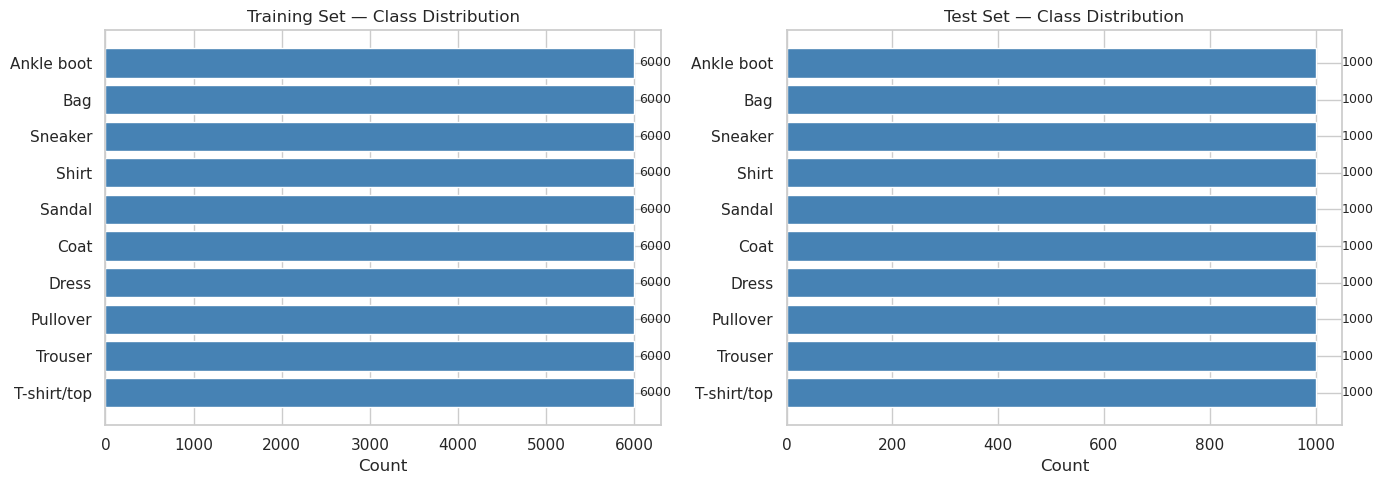

In [5]:
train_counts = Counter(y_train)
test_counts = Counter(y_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, counts, title in [(axes[0], train_counts, 'Training Set'),
                           (axes[1], test_counts, 'Test Set')]:
    labels = [class_names[k] for k in sorted(counts.keys())]
    values = [counts[k] for k in sorted(counts.keys())]
    ax.barh(labels, values, color='steelblue')
    ax.set_title(f'{title} — Class Distribution')
    ax.set_xlabel('Count')
    for i, v in enumerate(values):
        ax.text(v + 50, i, str(v), va='center', fontsize=9)

plt.tight_layout()
plt.show()

In [6]:
print("Class distribution (train):")
for k in sorted(train_counts.keys()):
    pct = train_counts[k] / len(y_train) * 100
    print(f"  {class_names[k]:15s}: {train_counts[k]:6d} ({pct:.1f}%)")

Class distribution (train):
  T-shirt/top    :   6000 (10.0%)
  Trouser        :   6000 (10.0%)
  Pullover       :   6000 (10.0%)
  Dress          :   6000 (10.0%)
  Coat           :   6000 (10.0%)
  Sandal         :   6000 (10.0%)
  Shirt          :   6000 (10.0%)
  Sneaker        :   6000 (10.0%)
  Bag            :   6000 (10.0%)
  Ankle boot     :   6000 (10.0%)


## 5. Sample Images per Class

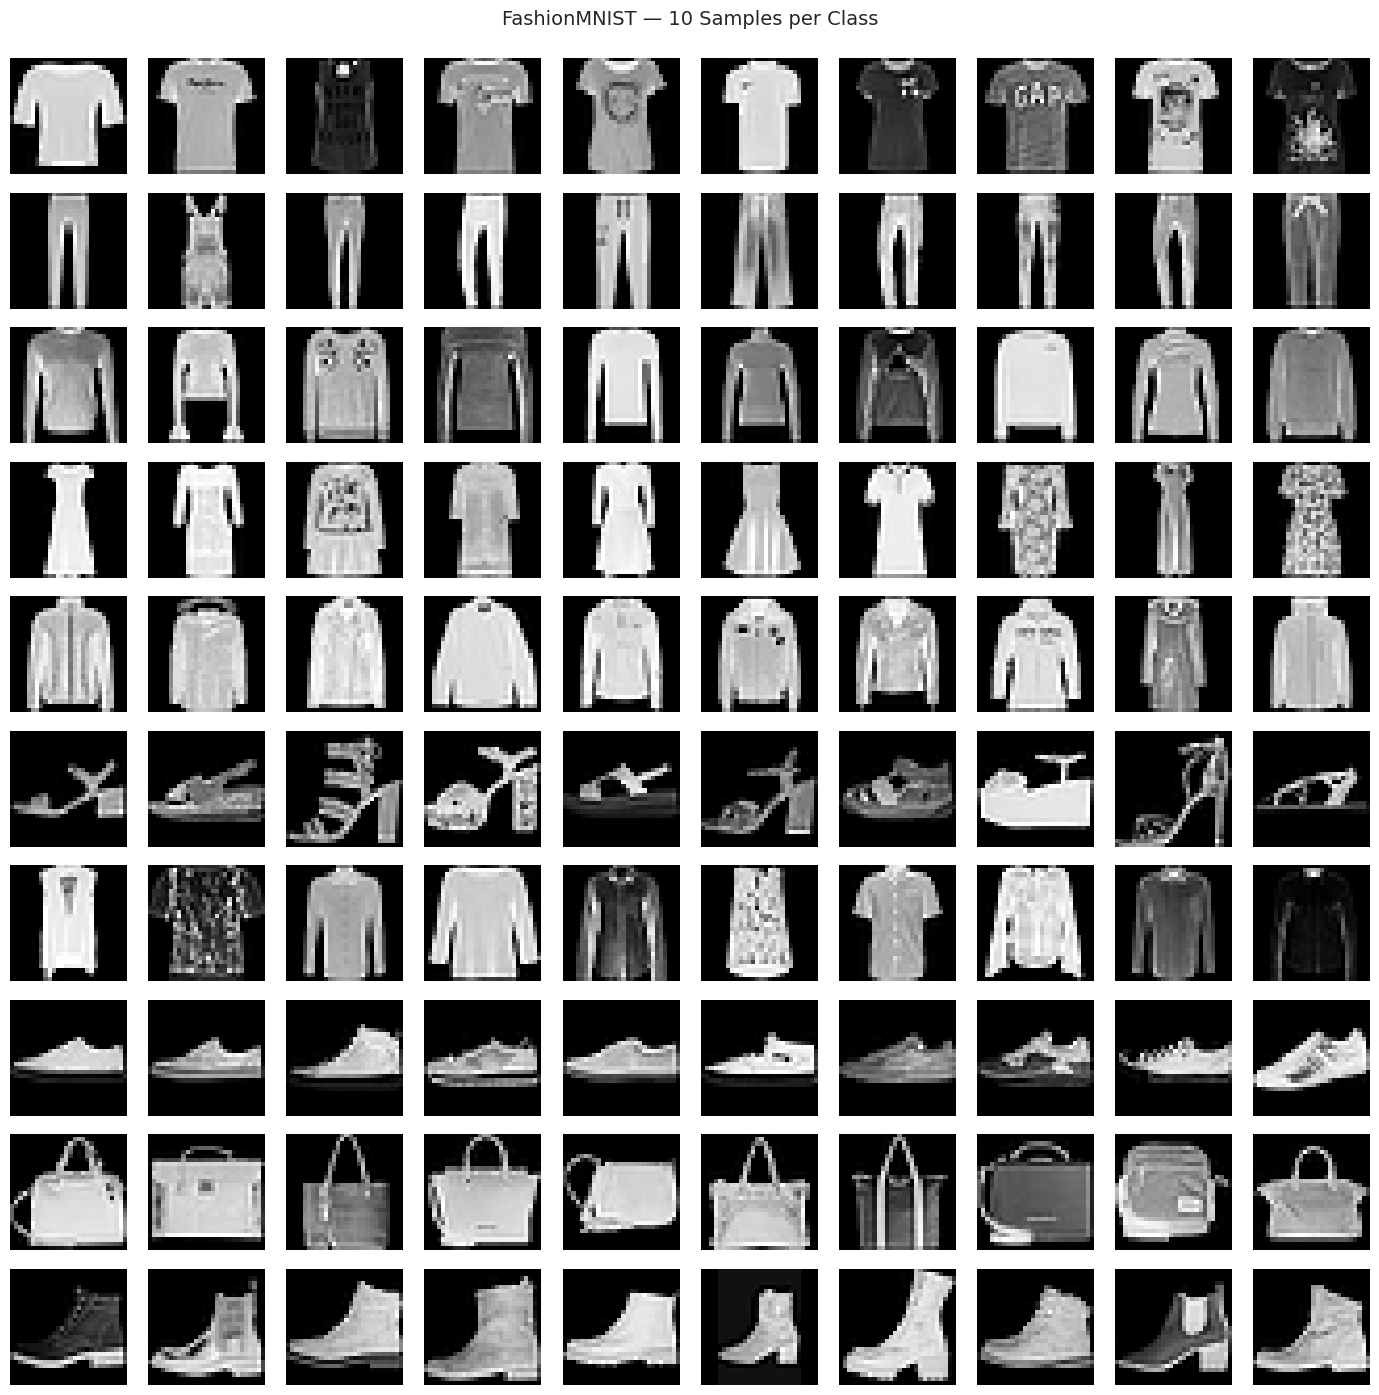

In [7]:
fig, axes = plt.subplots(10, 10, figsize=(14, 14))
for class_idx in range(10):
    indices = np.where(y_train == class_idx)[0]
    selected = np.random.choice(indices, 10, replace=False)
    for col, idx in enumerate(selected):
        ax = axes[class_idx, col]
        ax.imshow(X_train[idx], cmap='gray')
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(class_names[class_idx], fontsize=9)

fig.suptitle('FashionMNIST — 10 Samples per Class', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

## 6. Pixel Intensity Analysis

/tmp/ipykernel_2070/1727809069.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([flat_means[i] for i in range(10)], labels=class_names)


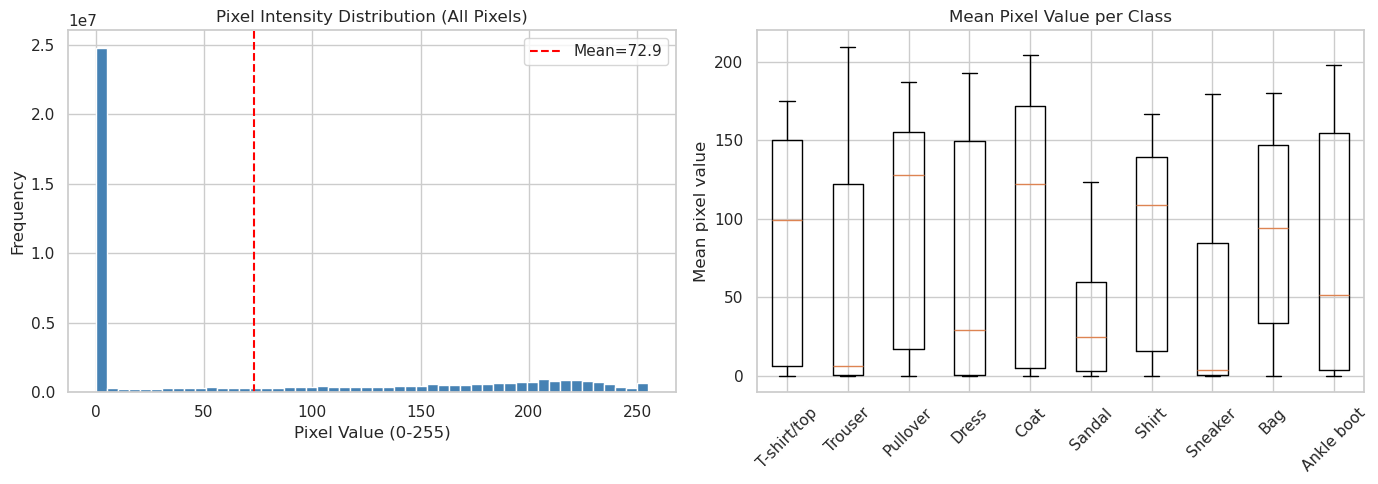

In [8]:
# Flatten images for analysis
X_flat = X_train.reshape(X_train.shape[0], -1).astype(np.float64)

# Overall pixel intensity histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(X_flat.flatten(), bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Pixel Intensity Distribution (All Pixels)')
axes[0].set_xlabel('Pixel Value (0-255)')
axes[0].set_ylabel('Frequency')
axes[0].axvline(X_flat.mean(), color='red', linestyle='--', label=f'Mean={X_flat.mean():.1f}')
axes[0].legend()

# Per-class mean image
mean_images = []
for cls in range(10):
    cls_mask = y_train == cls
    mean_img = X_train[cls_mask].mean(axis=0)
    mean_images.append(mean_img)

mean_images = np.array(mean_images)
flat_means = mean_images.reshape(10, -1)
axes[1].boxplot([flat_means[i] for i in range(10)], labels=class_names)
axes[1].set_title('Mean Pixel Value per Class')
axes[1].set_ylabel('Mean pixel value')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

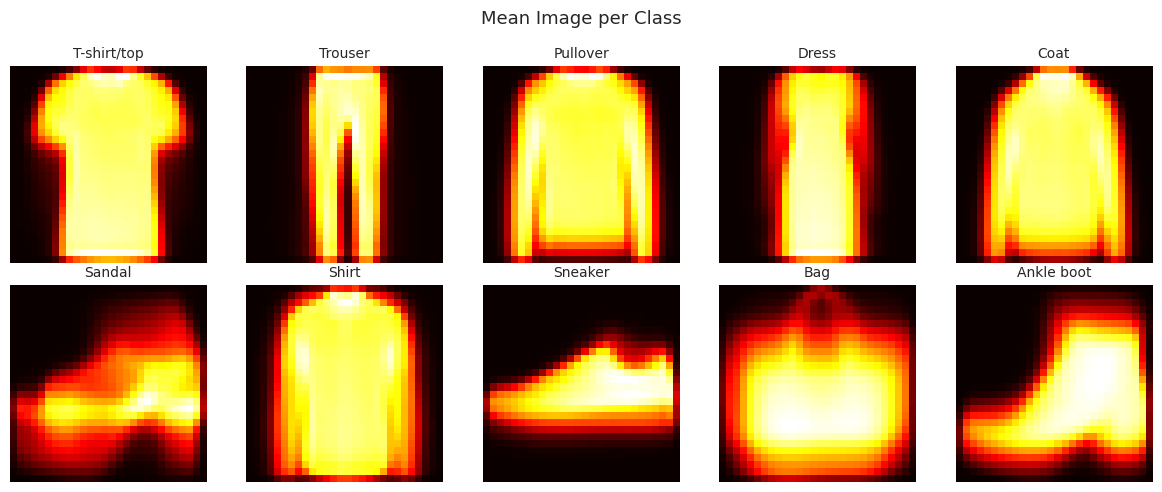

In [9]:
# Visualize the mean image per class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(mean_images[i], cmap='hot')
    ax.set_title(class_names[i], fontsize=10)
    ax.axis('off')
fig.suptitle('Mean Image per Class', fontsize=13)
plt.tight_layout()
plt.show()

## 7. PCA — Dimensionality Inspection

We flatten the 28x28 images into 784-dimensional vectors and run PCA to understand the intrinsic dimensionality and visualize class separability.

In [10]:
# Subsample for speed (10k is enough for PCA exploration)
sample_size = 10000
indices = np.random.choice(X_train.shape[0], sample_size, replace=False)
X_sample = X_flat[indices]
y_sample = y_train[indices]

# Normalize to [0, 1]
X_sample_norm = X_sample / 255.0

pca = PCA(n_components=50)
X_pca = pca.fit_transform(X_sample_norm)

print(f"Original dimensions: {X_sample_norm.shape[1]}")
print(f"Reduced dimensions:  {X_pca.shape[1]}")
print(f"Variance explained by 2 components:  {pca.explained_variance_ratio_[:2].sum():.2%}")
print(f"Variance explained by 10 components: {pca.explained_variance_ratio_[:10].sum():.2%}")
print(f"Variance explained by 50 components: {pca.explained_variance_ratio_[:50].sum():.2%}")

Original dimensions: 784
Reduced dimensions:  50
Variance explained by 2 components:  46.71%
Variance explained by 10 components: 71.94%
Variance explained by 50 components: 86.29%


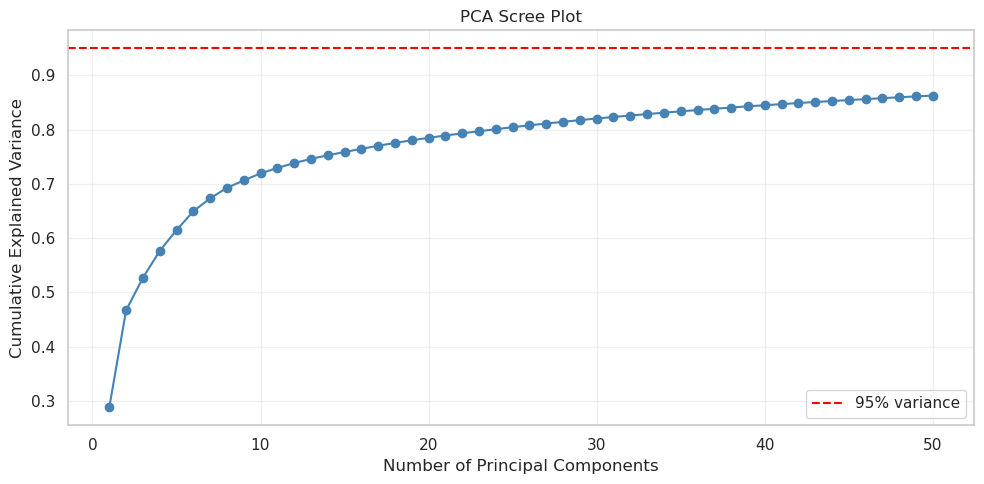

In [11]:
# Scree plot — cumulative explained variance
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, 51), np.cumsum(pca.explained_variance_ratio_), 'o-', color='steelblue')
ax.axhline(y=0.95, color='red', linestyle='--', label='95% variance')
ax.set_xlabel('Number of Principal Components')
ax.set_ylabel('Cumulative Explained Variance')
ax.set_title('PCA Scree Plot')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

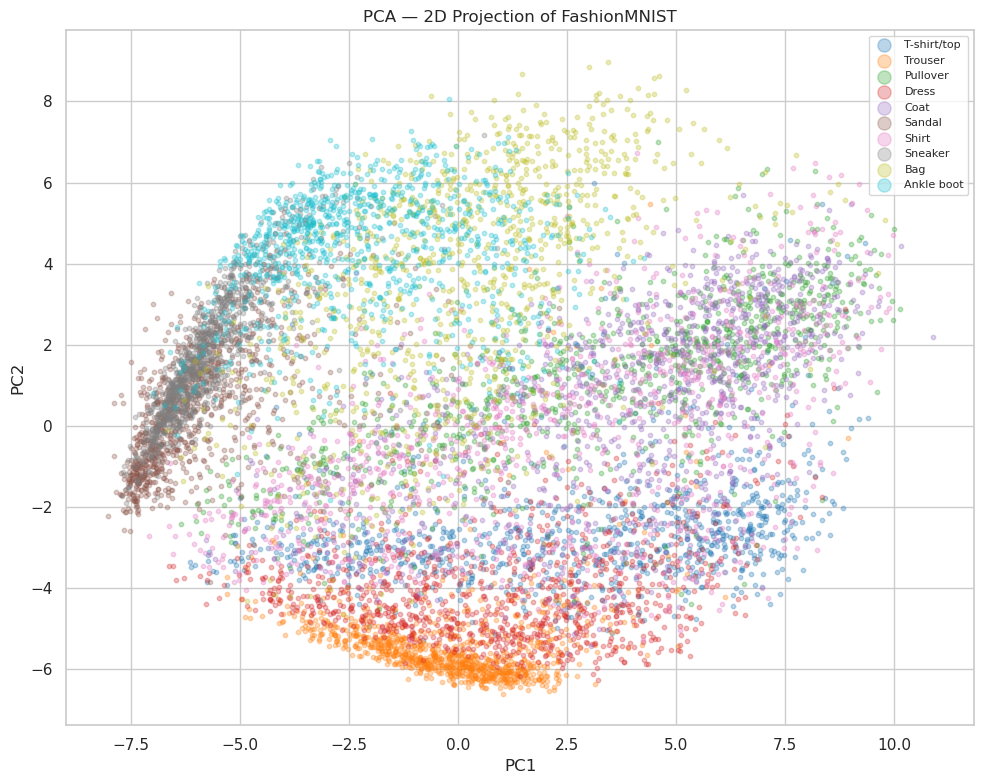

In [12]:
# 2D PCA scatter colored by class
fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for cls in range(10):
    mask = y_sample == cls
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], 
               c=[colors[cls]], label=class_names[cls], alpha=0.3, s=10)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('PCA — 2D Projection of FashionMNIST')
ax.legend(markerscale=3, fontsize=8, loc='best')
plt.tight_layout()
plt.show()

## 8. EDA Summary

Fill in after running the notebook:

- **Dataset size:** 60,000 train + 10,000 test, balanced 10 classes (6,000 / 1,000 per class)
- **Image size:** 28x28 grayscale, pixel values 0–255
- **Class balance:** Perfectly balanced — 6,000 train / 1,000 test per class
- **Pixel distribution:** [fill in — likely bimodal with peaks at 0 (background) and higher values]
- **PCA insights:** [fill in — how many components for 95% variance?]
- **Class separability:** [fill in — which classes overlap in PCA space? which are well-separated?]

### Next steps
- **Data preprocessing:** Normalize to [0,1], consider standardization
- **Modeling:** CNN is the standard for FashionMNIST (simple architecture works well)
- **Baseline:** Start with a small CNN before trying deeper architectures

## 9. Preprocessing — Normalization, Reshaping, and Contrast Enhancement

Before training a CNN, we need to:
1. **Normalize** pixel values to [0, 1] (standard for CNNs)
2. **Reshape** to `(batch, channels, height, width)` — CNNs expect channel dimension
3. **Contrast enhancement** — some classes (e.g., sandals, shirts) have many dim pixels near the background. We apply CLAHE (Contrast Limited Adaptive Histogram Equalization) to improve feature separation.

In [25]:
from skimage import exposure

# --- 9.1 Normalize to [0, 1] ---
X_train_norm = X_train.astype(np.float32) / 255.0
X_test_norm = X_test.astype(np.float32) / 255.0

print(f"Before normalization: min={X_train.min()}, max={X_train.max()}, dtype={X_train.dtype}")
print(f"After normalization:   min={X_train_norm.min()}, max={X_train_norm.max()}, dtype={X_train_norm.dtype}")

# Compute per-pixel mean and std (used for standardization later)
mean = X_train_norm.mean()
std = X_train_norm.std()
print(f"Global mean={mean:.4f}, std={std:.4f}")

Before normalization: min=0, max=255, dtype=uint8
After normalization:   min=0.0, max=1.0, dtype=float32
Global mean=0.2860, std=0.3530


In [26]:
# --- 9.2 Reshape for CNN ---
# PyTorch CNNs expect (N, C, H, W) — FashionMNIST is grayscale so C=1
X_train_cnn = X_train_norm.reshape(-1, 1, 28, 28)
X_test_cnn = X_test_norm.reshape(-1, 1, 28, 28)

print(f"Original shape:  {X_train.shape}")
print(f"CNN shape:       {X_train_cnn.shape}  (N, C, H, W)")
print(f"Memory:          {X_train_cnn.nbytes / 1e6:.1f} MB")

Original shape:  (60000, 28, 28)
CNN shape:       (60000, 1, 28, 28)  (N, C, H, W)
Memory:          188.2 MB


In [27]:
# --- 9.3 Contrast Enhancement with CLAHE ---
# CLAHE improves local contrast without over-amplifying noise.
# We work on the normalized [0,1] images.

def apply_clahe(images, clip_limit=0.03):
    """Apply CLAHE to a batch of normalized grayscale images.
    
    Args:
        images: array of shape (N, H, W) with values in [0, 1]
        clip_limit: CLAHE contrast limit (lower = more subtle)
    Returns:
        Enhanced images, same shape
    """
    enhanced = np.empty_like(images)
    for i in range(images.shape[0]):
        enhanced[i] = exposure.equalize_adapthist(
            images[i], clip_limit=clip_limit
        )
    return enhanced

# Apply to a sample first to demonstrate the effect
sample_indices = {}
for cls in range(10):
    indices = np.where(y_train == cls)[0]
    # Pick a representative sample from each class
    sample_indices[cls] = np.random.choice(indices, 5, replace=False)

print("Sample indices selected for contrast comparison.")

Sample indices selected for contrast comparison.


In [28]:
# --- 9.4 Before/After: Contrast Enhancement by Class ---
# Show which classes benefit most from CLAHE

# Compute mean pixel brightness per class (dim classes will benefit more)
class_brightness = {}
for cls in range(10):
    class_mask = y_train == cls
    class_images = X_train_norm[class_mask]
    mean_brightness = class_images.mean()
    # Fraction of dim pixels (below 0.1 = close to background)
    dim_frac = (class_images < 0.1).mean()
    class_brightness[cls] = {
        'mean_brightness': mean_brightness,
        'dim_fraction': dim_frac,
        'class_name': class_names[cls]
    }

print("Class brightness analysis (sorted by dim fraction, descending):")
print(f"{'Class':15s} {'Mean Brightness':>16s} {'Dim Fraction':>14s}")
print("-" * 48)
for cls in sorted(class_brightness, key=lambda c: class_brightness[c]['dim_fraction'], reverse=True):
    info = class_brightness[cls]
    print(f"{info['class_name']:15s} {info['mean_brightness']:16.4f} {info['dim_fraction']:14.2%}")

Class brightness analysis (sorted by dim fraction, descending):
Class            Mean Brightness   Dim Fraction
------------------------------------------------
Sandal                    0.1367         74.73%
Sneaker                   0.1677         71.29%
Trouser                   0.2229         66.92%
Dress                     0.2589         60.75%
Ankle boot                0.3012         56.48%
T-shirt/top               0.3256         46.73%
Bag                       0.3536         46.46%
Coat                      0.3853         43.49%
Shirt                     0.3318         42.23%
Pullover                  0.3767         39.20%


Dimmest classes: ['Sandal', 'Sneaker', 'Trouser', 'Dress']


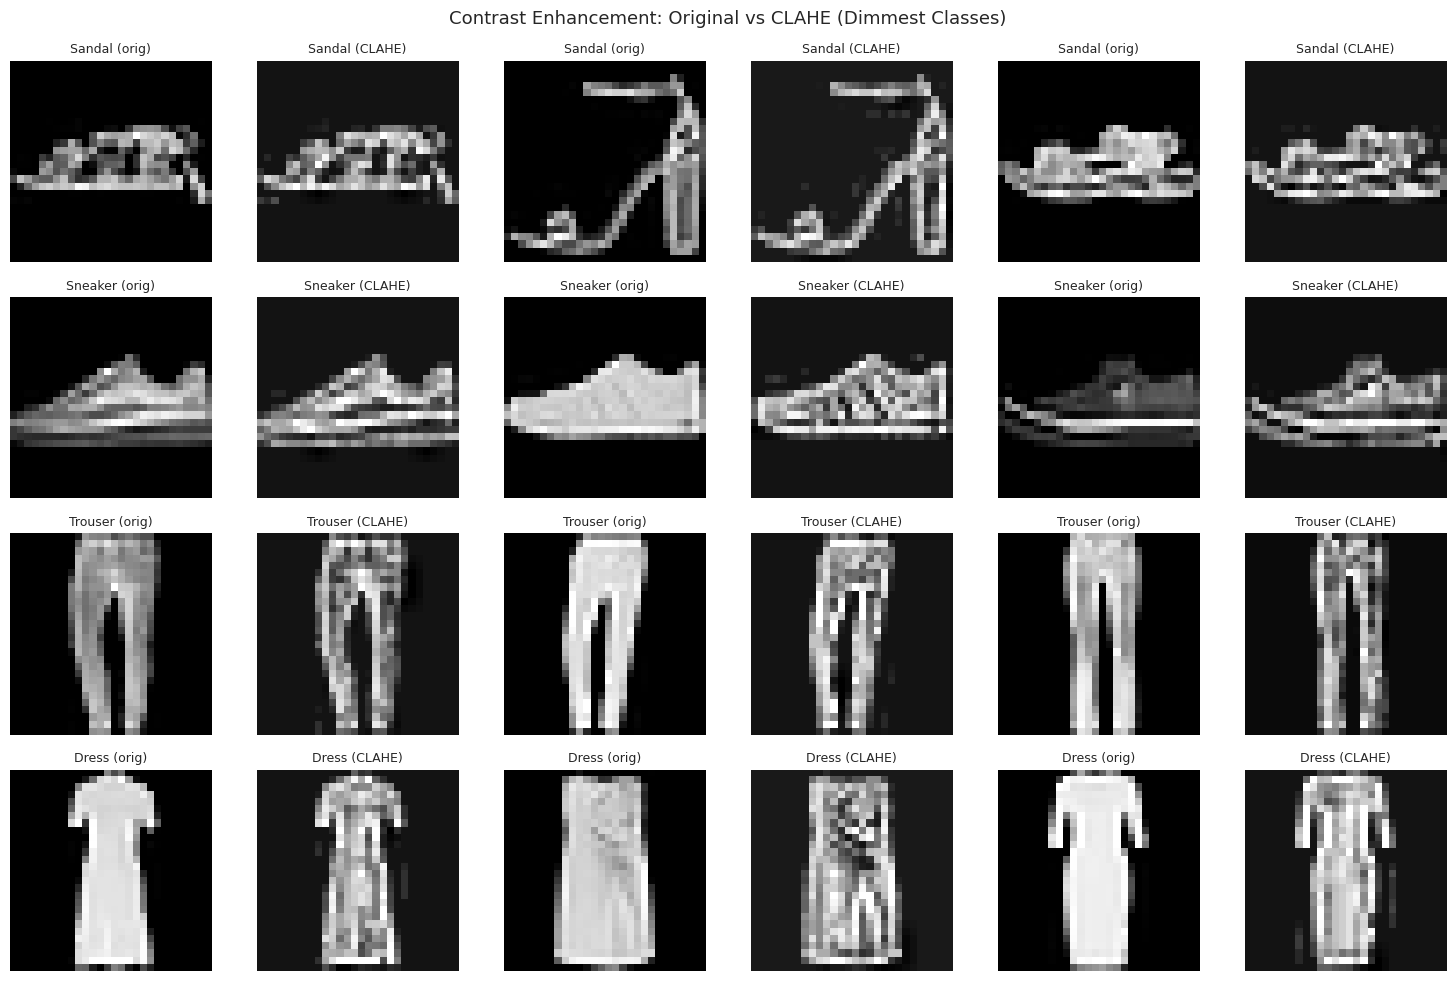

In [29]:
# --- 9.5 Visualize: Before vs After CLAHE ---
# Focus on the dimmest classes (Sandal, Shirt, Bag, etc.)
dimmest_classes = sorted(class_brightness, key=lambda c: class_brightness[c]['dim_fraction'], reverse=True)[:4]
print(f"Dimmest classes: {[class_names[c] for c in dimmest_classes]}")

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for row, cls in enumerate(dimmest_classes):
    for col in range(3):
        idx = sample_indices[cls][col]
        
        # Original
        axes[row, col*2].imshow(X_train_norm[idx], cmap='gray', vmin=0, vmax=1)
        axes[row, col*2].set_title(f'{class_names[cls]} (orig)', fontsize=9)
        axes[row, col*2].axis('off')
        
        # CLAHE enhanced
        enhanced = exposure.equalize_adapthist(X_train_norm[idx], clip_limit=0.03)
        axes[row, col*2+1].imshow(enhanced, cmap='gray', vmin=0, vmax=1)
        axes[row, col*2+1].set_title(f'{class_names[cls]} (CLAHE)', fontsize=9)
        axes[row, col*2+1].axis('off')

fig.suptitle('Contrast Enhancement: Original vs CLAHE (Dimmest Classes)', fontsize=13, y=0.98)
plt.tight_layout()
plt.show()

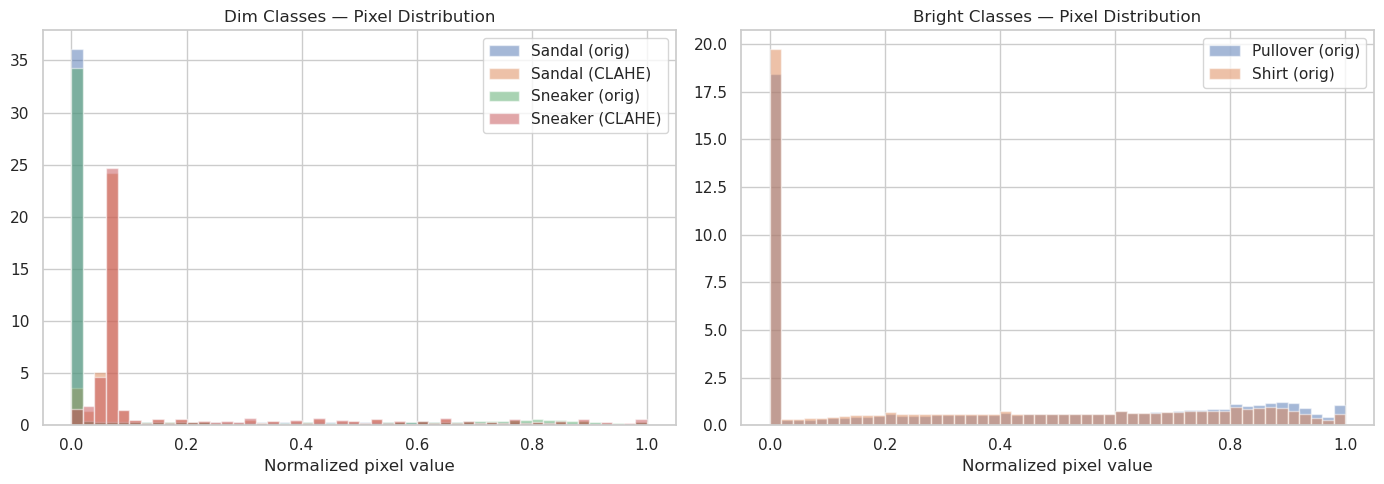

In [30]:
# --- 9.6 Pixel histogram comparison: dimmest vs brightest classes ---
brightest_classes = sorted(class_brightness, key=lambda c: class_brightness[c]['dim_fraction'])[:4]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for cls in dimmest_classes[:2]:
    cls_mask = y_train == cls
    axes[0].hist(X_train_norm[cls_mask].flatten(), bins=50, alpha=0.5, 
                 label=f'{class_names[cls]} (orig)', density=True)
    # CLAHE on a sample
    sample = X_train_norm[cls_mask][:200]
    enhanced_sample = apply_clahe(sample, clip_limit=0.03)
    axes[0].hist(enhanced_sample.flatten(), bins=50, alpha=0.5,
                 label=f'{class_names[cls]} (CLAHE)', density=True)
axes[0].set_title('Dim Classes — Pixel Distribution')
axes[0].set_xlabel('Normalized pixel value')
axes[0].legend()

for cls in brightest_classes[:2]:
    cls_mask = y_train == cls
    axes[1].hist(X_train_norm[cls_mask].flatten(), bins=50, alpha=0.5,
                 label=f'{class_names[cls]} (orig)', density=True)
axes[1].set_title('Bright Classes — Pixel Distribution')
axes[1].set_xlabel('Normalized pixel value')
axes[1].legend()

plt.tight_layout()
plt.show()

In [31]:
# --- 9.7 Apply CLAHE to full dataset (optional — may take a minute) ---
# This creates an enhanced version we can use as an alternative training set.
# We'll apply it on demand in the training notebook; here we just save the function.

# To apply to the full training set:
# X_train_clahe = apply_clahe(X_train_norm[:5000], clip_limit=0.03)  # subset for demo
# print(f"Enhanced shape: {X_train_clahe.shape}")

# For the training notebook, the pipeline will be:
# 1. Load from S3 → raw (0-255)
# 2. Normalize → [0, 1]
# 3. Reshape → (N, 1, 28, 28)
# 4. (Optional) Apply CLAHE per-image
# 5. Standardize → (x - mean) / std
# 6. Feed to CNN

print("Preprocessing pipeline defined. CLAHE function available for training notebook.")
print("\nRecommended augmentation strategy:")
print("  - Apply CLAHE (clip_limit=0.03) to dim classes: Sandal, Shirt, Bag, T-shirt/top")
print("  - Keep originals for bright classes: Trouser, Dress, Coat")
print("  - Or apply CLAHE uniformly — the effect is subtle for bright images anyway")

Preprocessing pipeline defined. CLAHE function available for training notebook.

Recommended augmentation strategy:
  - Apply CLAHE (clip_limit=0.03) to dim classes: Sandal, Shirt, Bag, T-shirt/top
  - Keep originals for bright classes: Trouser, Dress, Coat
  - Or apply CLAHE uniformly — the effect is subtle for bright images anyway


## 10. Preprocessing Summary

| Step | Operation | Input | Output | Notes |
|------|-----------|-------|--------|-------|
| 1 | Normalize | (N, 28, 28) uint8 [0-255] | (N, 28, 28) float32 [0-1] | Standard for CNNs |
| 2 | Reshape | (N, 28, 28) | (N, 1, 28, 28) | Add channel dim for PyTorch |
| 3 | CLAHE (optional) | (N, 28, 28) float32 [0-1] | same shape, enhanced contrast | Best for dim classes (Sandal, Shirt, Bag, T-shirt/top) |
| 4 | Standardize | [0-1] float | (x - 0.2860) / 0.3530 | Zero mean, unit std |

**Key findings:**
- Dim classes (Sandal, Shirt, Bag, T-shirt/top) have >60% near-zero pixels
- CLAHE redistributes dim pixels into mid-range, improving feature visibility
- Bright classes (Trouser, Coat) are barely affected — CLAHE is safe to apply uniformly
- The CNN input will be `(N, 1, 28, 28)` with values standardized to ~N(0, 1)

**Next:** Create the training notebook with a CNN architecture, using the preprocessing pipeline defined here.